# Airbnb New York City: Data Cleaning & Exploratory Analysis

**Authors:** Adam Elmalek, Mohammed Younis

Analysis of ~36,000 Airbnb listings in New York City (Inside Airbnb, June 2025 snapshot):
data cleaning, outlier handling, feature engineering, visual EDA and hypothesis checks.

The city was selected by `src/select_city.py` (digit sum of team IDs % 26 → letter **N** → New York City).

## 1. Setup & paths
Works both locally (repo folders) and in Google Colab (Drive).

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:  # Running in Google Colab -> use the project folder on Drive
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/airbnb_adam_mohammed')
except ImportError:  # Running locally -> repo root (notebook lives in notebooks/)
    BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

DATA_RAW = BASE / 'data' / 'raw'
DATA_CLEAN = BASE / 'data' / 'clean'
FIG_DIR = BASE / 'outputs' / 'figures'
for p in (DATA_RAW, DATA_CLEAN, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
print('BASE:', BASE)

BASE: /tmp/airrepo


## 2. Load data

In [2]:
sel = BASE / 'data' / 'selected_city.txt'
CITY = sel.read_text(encoding='utf-8').strip() if sel.exists() else 'New York City'
print('CITY:', CITY)

candidates = [DATA_RAW / 'listings.csv', DATA_RAW / 'listings.csv.gz']
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError(f'Put listings.csv (or .csv.gz) from insideairbnb.com in {DATA_RAW}')

df = pd.read_csv(path, low_memory=False)
print('Shape (rows, cols):', df.shape)
df.head()

CITY: New York City
Shape (rows, cols): (36322, 18)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,2539,Superfast Wi-Fi. Clean & quiet home by the park,2787,John,Brooklyn,Kensington,40.64529,-73.97238,Private room,285.0,30,9,2018-10-19,0.08,6,347,0,NaN
1,2595,Skylit Midtown Manhattan Spacious Studio,2845,Jennifer,Manhattan,Midtown,40.75356,-73.98559,Entire home/apt,240.0,30,49,2022-06-21,0.26,3,312,0,NaN
2,5136,Spacious Family Friendly Duplex w/ Patio + Yard,7378,Rebecca,Brooklyn,Sunset Park,40.66265,-73.99454,Entire home/apt,215.0,30,4,2023-08-20,0.03,1,80,0,NaN
3,6848,Only 2 stops to Manhattan studio,15991,Allen,Brooklyn,Williamsburg,40.70935,-73.95342,Entire home/apt,97.0,30,196,2025-06-09,1.00,1,219,4,NaN
4,6872,Uptown Sanctuary w/ Private Bath (Month to Month),16104,Kahshanna,Manhattan,East Harlem,40.80107,-73.94255,Private room,NaN,30,1,2022-06-05,0.03,2,2,0,NaN


## 3. Data types, statistics, unique values

In [3]:
print(df.dtypes, '\n')
display(df.describe(include=[np.number]).T)

uniques = df.nunique(dropna=False).rename('unique_values')
display(uniques.to_frame())

id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                             float64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                               str
dtype: object 



,count,mean,std,min,25%,50%,75%,max
id,36322.0,4.382216e+17,5.199100e+17,2539.000000,2.121091e+07,5.004978e+07,9.277467e+17,1.444534e+18
host_id,36322.0,1.713590e+08,1.893709e+08,1678.000000,1.764159e+07,8.336440e+07,3.036223e+08,7.005911e+08
latitude,36322.0,4.072856e+01,5.648223e-02,40.500366,4.068828e+01,4.072594e+01,4.076235e+01,4.091139e+01
longitude,36322.0,-7.394697e+01,5.525153e-02,-74.251907,-7.398326e+01,-7.395471e+01,-7.392785e+01,-7.371182e+01
price,21459.0,5.215284e+02,3.501385e+03,8.000000,8.900000e+01,1.540000e+02,2.700000e+02,5.018400e+04
minimum_nights,36322.0,2.920572e+01,3.511100e+01,1.000000,3.000000e+01,3.000000e+01,3.000000e+01,1.124000e+03
number_of_reviews,36322.0,2.685304e+01,6.738206e+01,0.000000,0.000000e+00,3.000000e+00,2.300000e+01,3.277000e+03
reviews_per_month,25171.0,8.172615e-01,1.850794e+00,0.010000,8.000000e-02,2.600000e-01,9.400000e-01,1.219700e+02
calculated_host_listings_count,36322.0,6.070415e+01,1.950884e+02,1.000000,1.000000e+00,1.000000e+00,8.000000e+00,1.054000e+03
availability_365,36322.0,1.590105e+02,1.455351e+02,0.000000,0.000000e+00,1.530000e+02,3.100000e+02,3.650000e+02


,unique_values
id,36322
name,34733
host_id,21795
host_name,8377
neighbourhood_group,5
neighbourhood,223
latitude,22551
longitude,20416
room_type,4
price,1102


## 4. Rename columns & identify variable types

In [4]:
rename_map = {
    'calculated_host_listings_count': 'host_listings_count',
    'neighbourhood_group': 'borough',
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})
print('Renamed:', rename_map)

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric:', num_cols)
print('Categorical:', cat_cols)

Renamed: {'calculated_host_listings_count': 'host_listings_count', 'neighbourhood_group': 'borough'}
Numeric: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'host_listings_count', 'availability_365', 'number_of_reviews_ltm']
Categorical: ['name', 'host_name', 'borough', 'neighbourhood', 'room_type', 'last_review', 'license']


## 5. Cleaning: missing values, types, duplicates, impossible values

**Fix vs. original version:** the original filled every missing numeric value with the column mean.
About 41% of listings have no price, so this invented a fake "average" price for thousands of listings
and distorted every price chart. Now:
- listings **without a price are dropped** (price is the target of the analysis),
- `reviews_per_month` missing means *no reviews* → filled with **0**,
- other columns are left as-is.

In [5]:
def missing_table(d):
    miss = d.isna().sum()
    out = pd.DataFrame({'missing': miss, 'missing_%': (miss / len(d) * 100).round(2)})
    return out[out['missing'] > 0].sort_values('missing', ascending=False)

display(missing_table(df))

# Types: price may come as "$1,234.00" in some Inside Airbnb exports
if df['price'].dtype == object:
    df['price'] = pd.to_numeric(df['price'].str.replace(r'[$,]', '', regex=True), errors='coerce')
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')

rows0 = len(df)
df = df.drop_duplicates(subset='id')
print('Duplicates removed:', rows0 - len(df))

rows0 = len(df)
df = df.dropna(subset=['price'])
print('Listings without price removed:', rows0 - len(df))

df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Impossible values
rows0 = len(df)
df = df[(df['price'] > 0) & (df['minimum_nights'].between(1, 365))]
print('Impossible values removed (price<=0 or min nights outside 1-365):', rows0 - len(df))
print('Shape after cleaning:', df.shape)

,missing,missing_%
license,30993,85.33
price,14863,40.92
last_review,11151,30.70
reviews_per_month,11151,30.70
host_name,15,0.04
name,2,0.01


Duplicates removed: 0
Listings without price removed: 14863
Impossible values removed (price<=0 or min nights outside 1-365): 34
Shape after cleaning: (21425, 18)


## 6. Outliers (price)
Prices are heavily right-skewed, so the Z-score is computed on **log(price)**; listings with |z| > 3 are removed.

In [6]:
log_p = np.log(df['price'])
z = (log_p - log_p.mean()) / log_p.std()
rows0 = len(df)
df = df[z.abs() <= 3]
print('Outliers removed:', rows0 - len(df))
print(df['price'].describe().round(2))

Outliers removed: 211
count    21214.00
mean       218.83
std        223.47
min         14.00
25%         89.00
50%        152.00
75%        264.00
max       2597.00
Name: price, dtype: float64


## 7. Feature engineering

In [7]:
# 1) price_category: Low / Medium / High by tertiles
q1, q2 = df['price'].quantile([1/3, 2/3])
df['price_category'] = pd.cut(df['price'], [-np.inf, q1, q2, np.inf], labels=['Low', 'Medium', 'High'])

# 2) reviews_intensity: reviews per month (0 when the listing has no reviews)
df['reviews_intensity'] = df['reviews_per_month']

# 3) is_long_min_stay: minimum stay of 30+ nights (NYC short-term rental law, Local Law 18)
df['is_long_min_stay'] = (df['minimum_nights'] >= 30).astype(int)

# 4) is_multi_host: host manages more than one listing (likely commercial)
df['is_multi_host'] = (df['host_listings_count'] > 1).astype(int)

print(f'Price tertiles: Low <= ${q1:.0f} < Medium <= ${q2:.0f} < High')
df[['price', 'price_category', 'reviews_intensity', 'is_long_min_stay', 'is_multi_host']].head()

Price tertiles: Low <= $108 < Medium <= $218 < High


,price,price_category,reviews_intensity,is_long_min_stay,is_multi_host
0,285.0,High,0.08,1,1
1,240.0,High,0.26,1,1
2,215.0,Medium,0.03,1,0
3,97.0,Low,1.00,1,0
5,63.0,Low,1.33,1,0


## 8. Univariate EDA

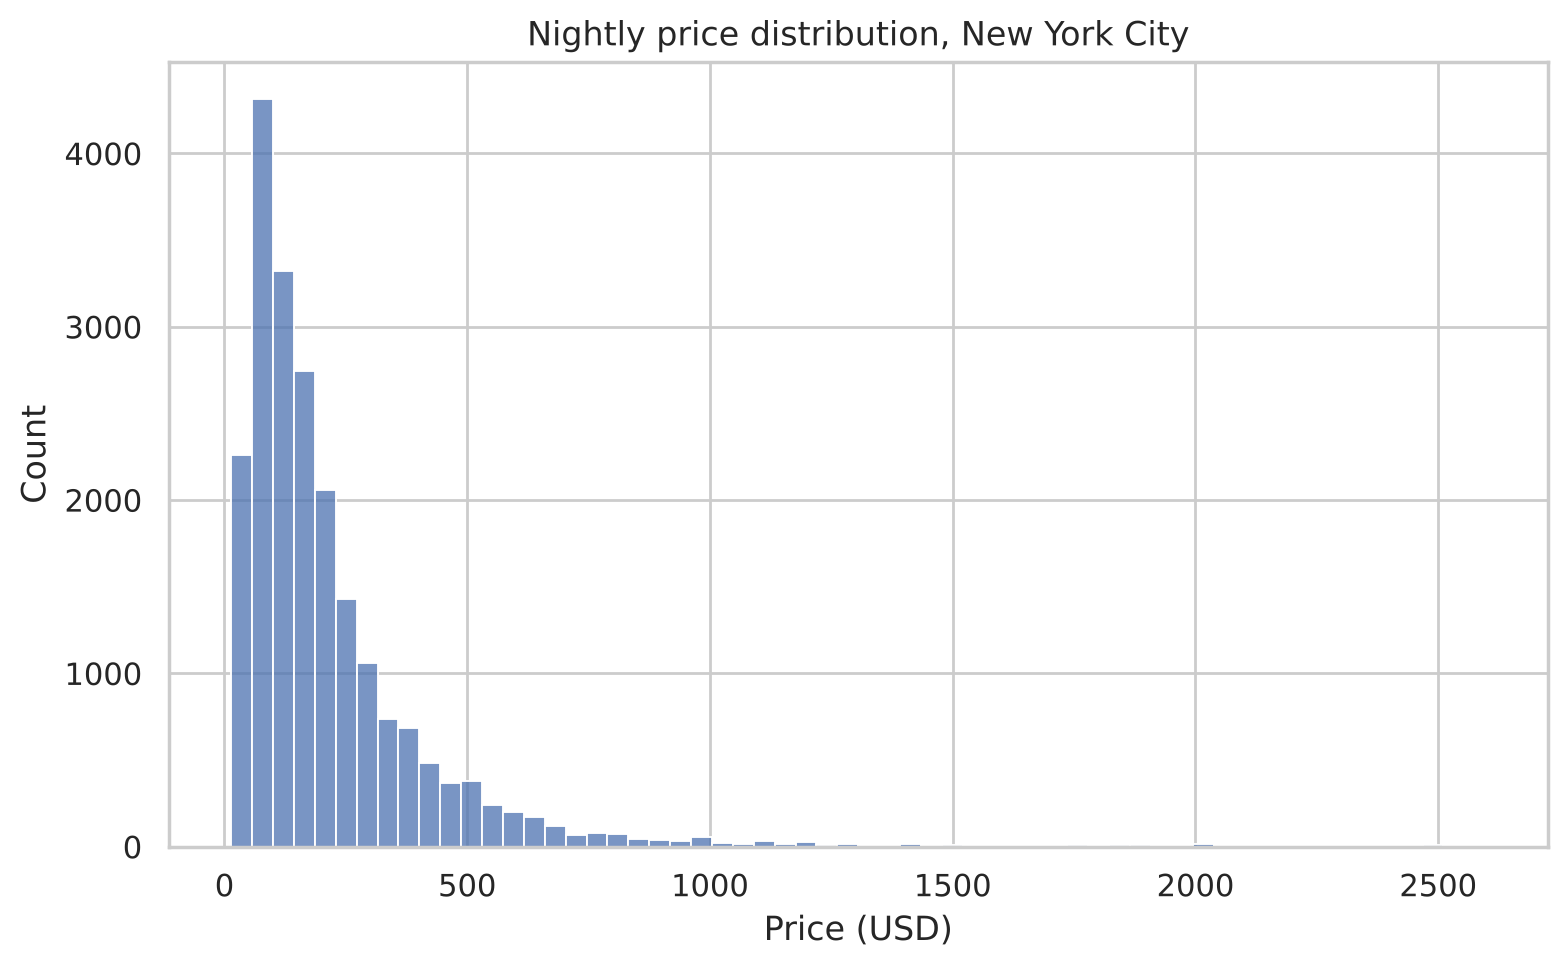

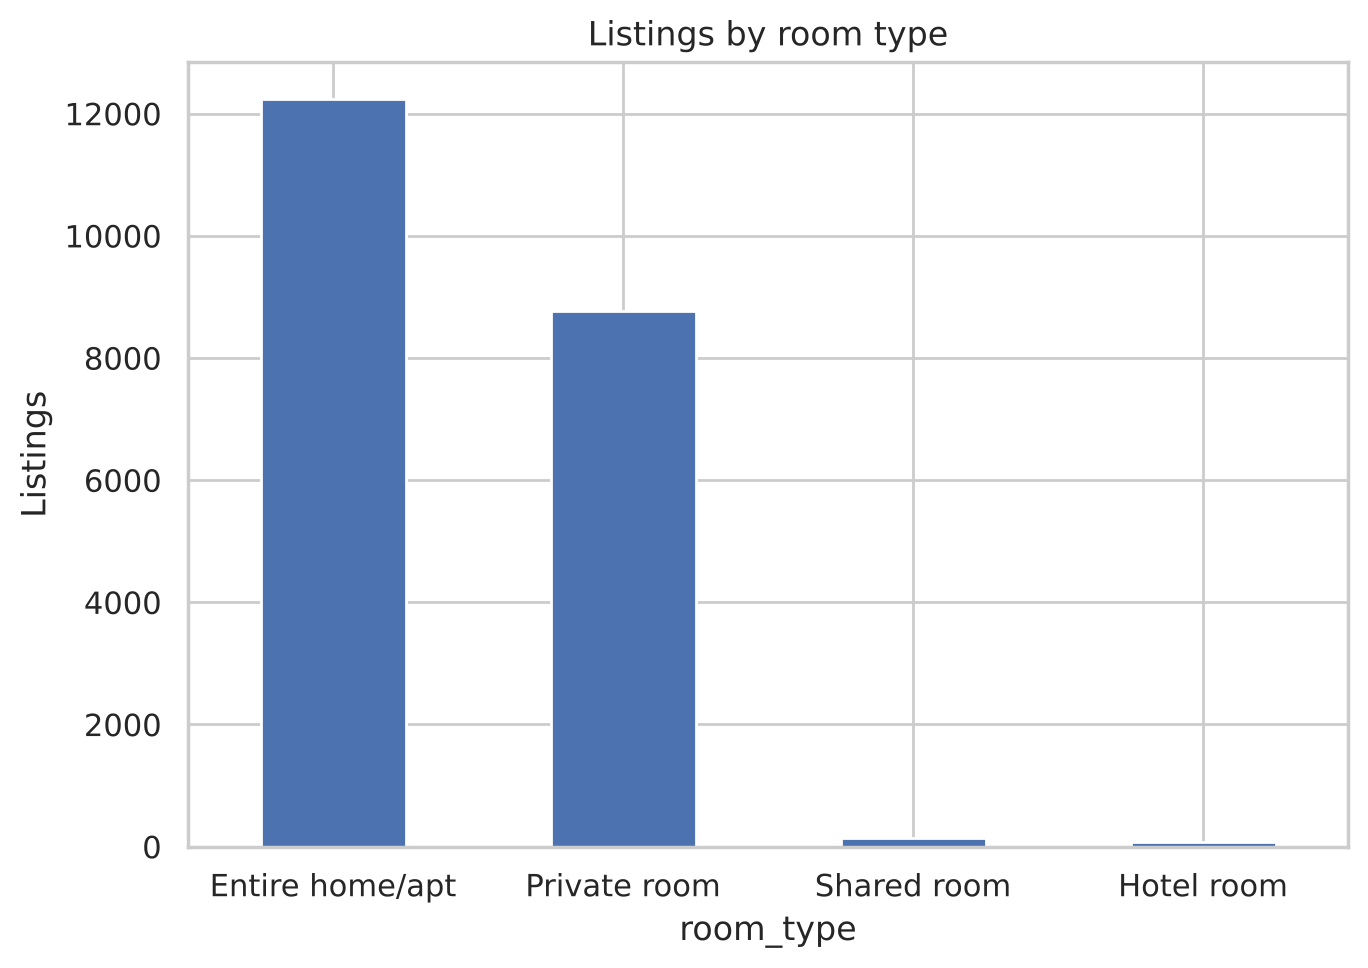

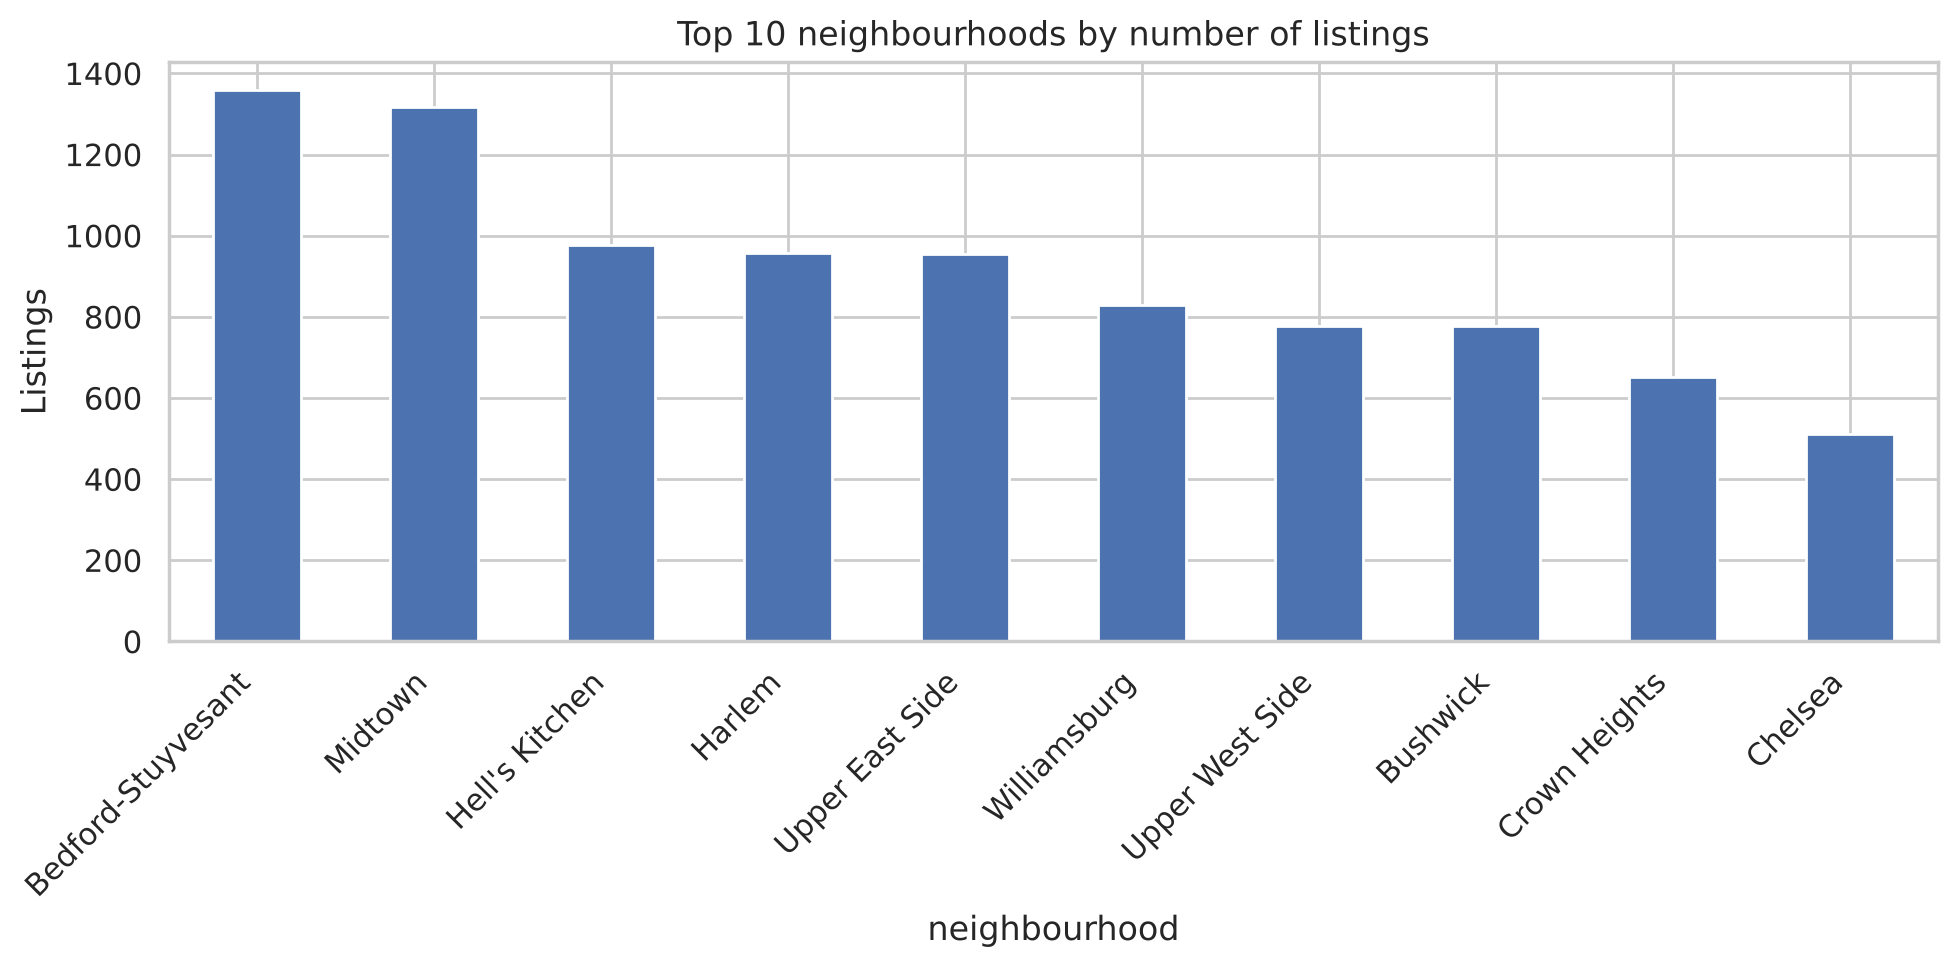

In [8]:
def save_show(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=120, bbox_inches='tight')
    plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=60)
plt.title(f'Nightly price distribution, {CITY}'); plt.xlabel('Price (USD)')
save_show('price_hist.png')

plt.figure(figsize=(7, 5))
df['room_type'].value_counts().plot(kind='bar', color=sns.color_palette()[0])
plt.title('Listings by room type'); plt.ylabel('Listings'); plt.xticks(rotation=0)
save_show('room_type_bar.png')

plt.figure(figsize=(10, 5))
df['neighbourhood'].value_counts().head(10).plot(kind='bar', color=sns.color_palette()[0])
plt.title('Top 10 neighbourhoods by number of listings'); plt.ylabel('Listings')
plt.xticks(rotation=45, ha='right')
save_show('top10_neighbourhood.png')

## 9. Bivariate EDA: price vs. location, room type and reviews

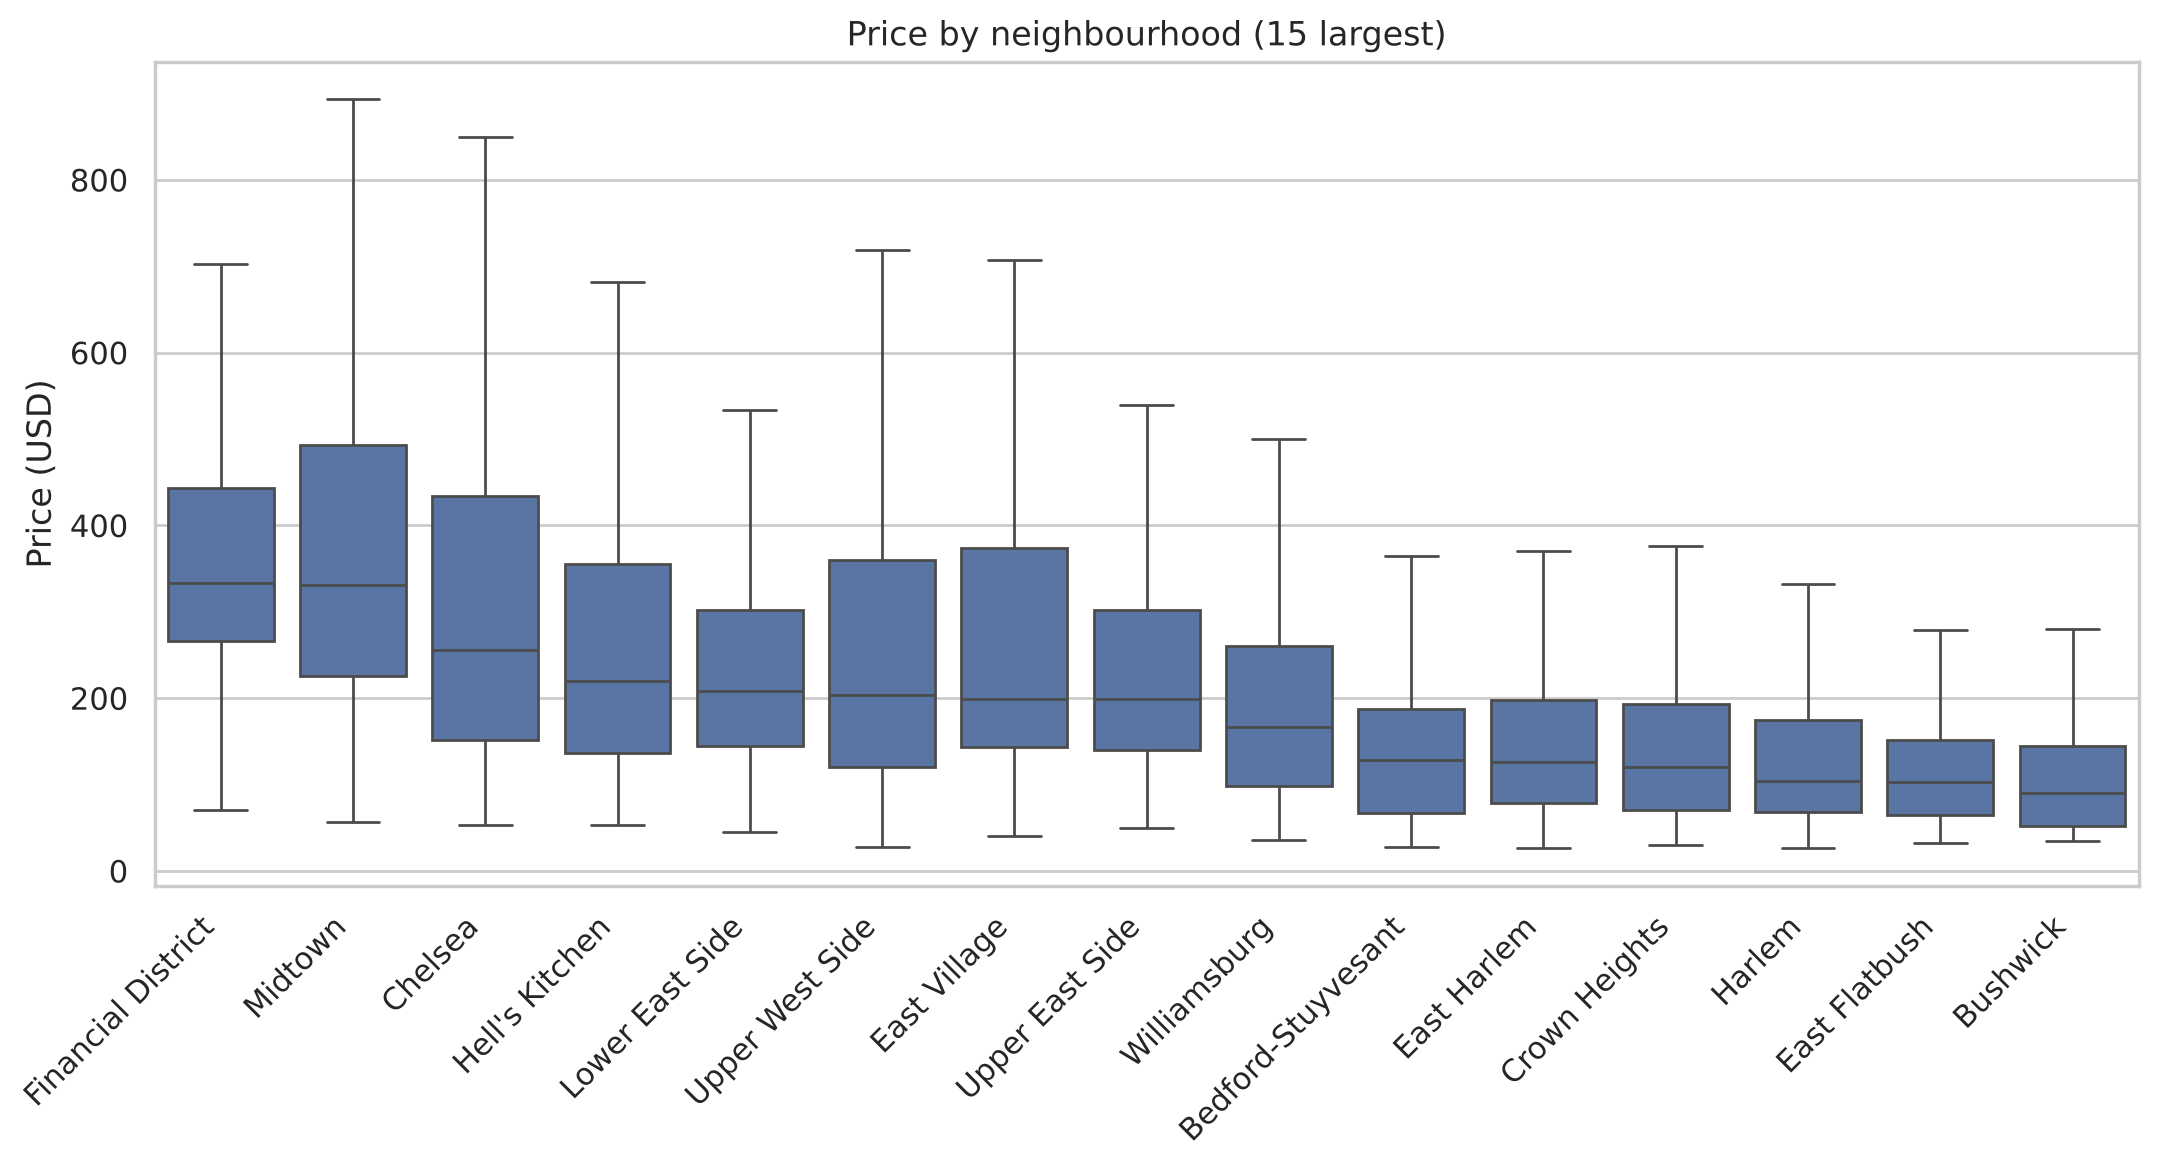

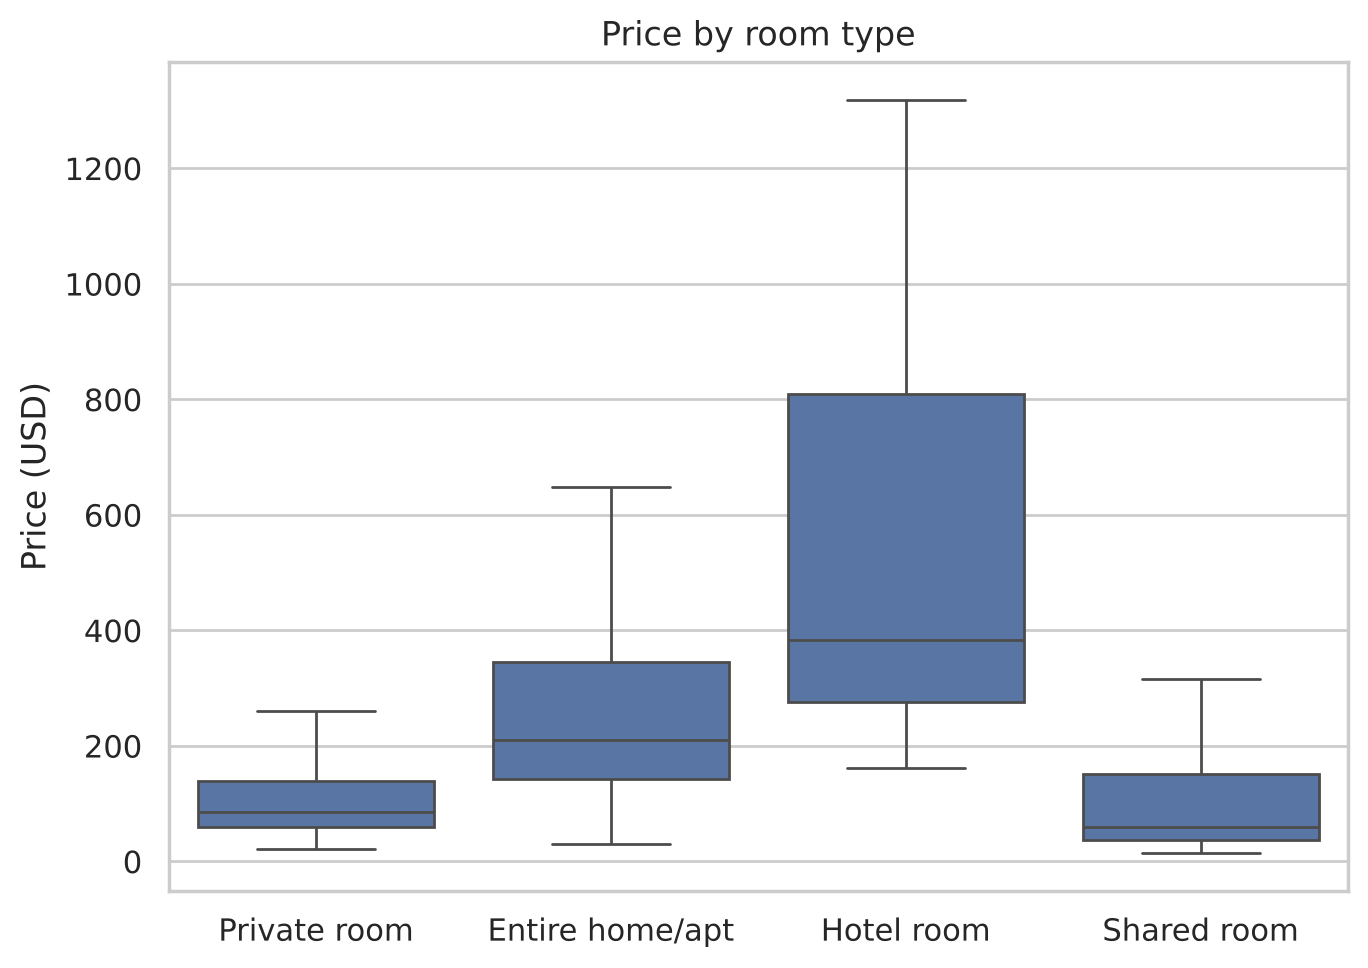

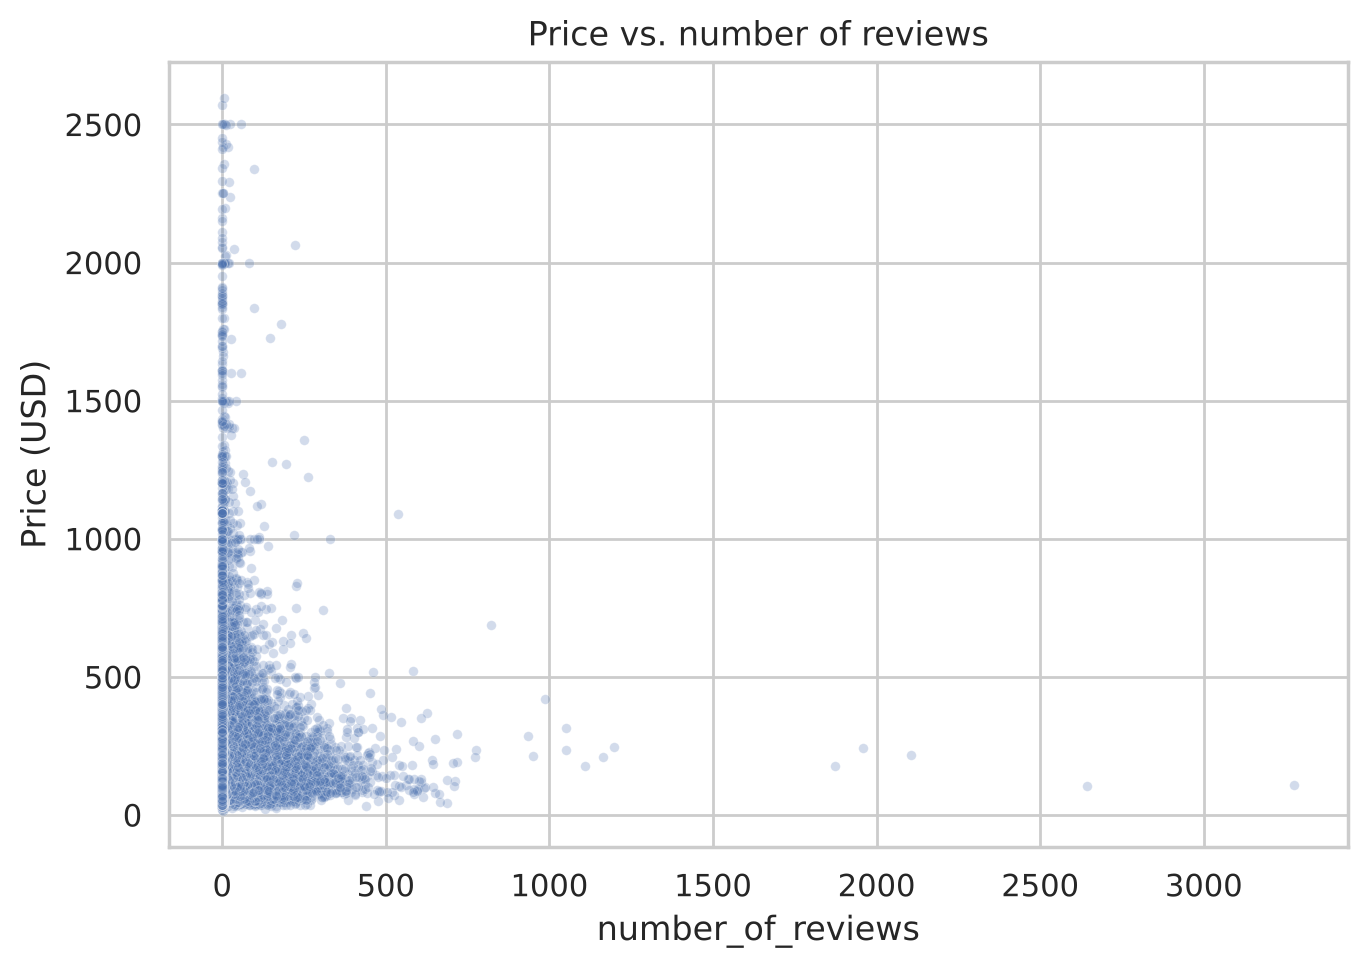

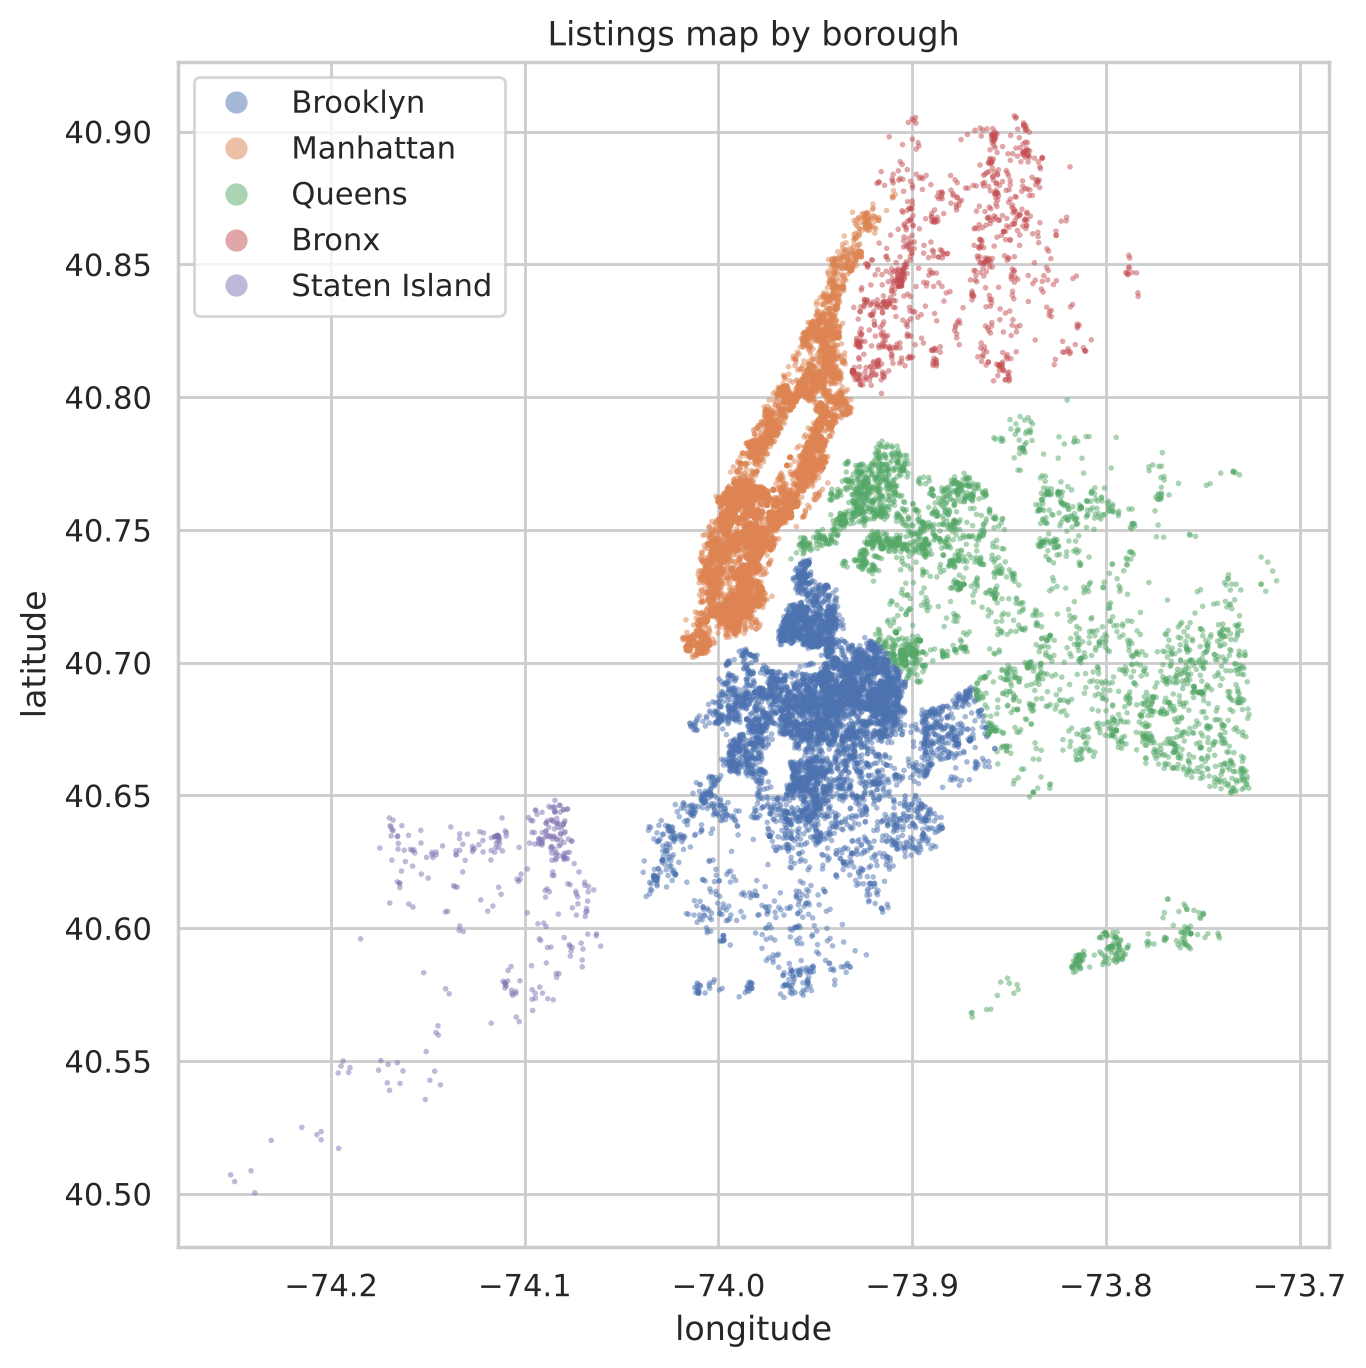

In [9]:
top15 = df['neighbourhood'].value_counts().head(15).index
order = df[df['neighbourhood'].isin(top15)].groupby('neighbourhood')['price'].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 6))
sns.boxplot(data=df[df['neighbourhood'].isin(top15)], x='neighbourhood', y='price', order=order, showfliers=False)
plt.xticks(rotation=45, ha='right')
plt.title('Price by neighbourhood (15 largest)'); plt.ylabel('Price (USD)'); plt.xlabel('')
save_show('price_by_neighbourhood_box.png')

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='room_type', y='price', showfliers=False)
plt.title('Price by room type'); plt.ylabel('Price (USD)'); plt.xlabel('')
save_show('price_by_room_type_box.png')

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='number_of_reviews', y='price', alpha=0.25, s=12)
plt.title('Price vs. number of reviews'); plt.ylabel('Price (USD)')
save_show('price_vs_reviews_scatter.png')

plt.figure(figsize=(7, 7))
sns.scatterplot(data=df, x='longitude', y='latitude', hue='borough', s=4, alpha=0.5, linewidth=0)
plt.title('Listings map by borough'); plt.legend(markerscale=4)
save_show('listings_map.png')

## 10. Inactive listings (no review in the last 24 months)
**Fix vs. original version:** the reference date is now the date the data was collected
(the latest review in the file), not *today*. Measuring from today wrongly marked active listings as inactive.

Data snapshot date: 2025-06-17
Inactive listings: 8,281 (39.0%)


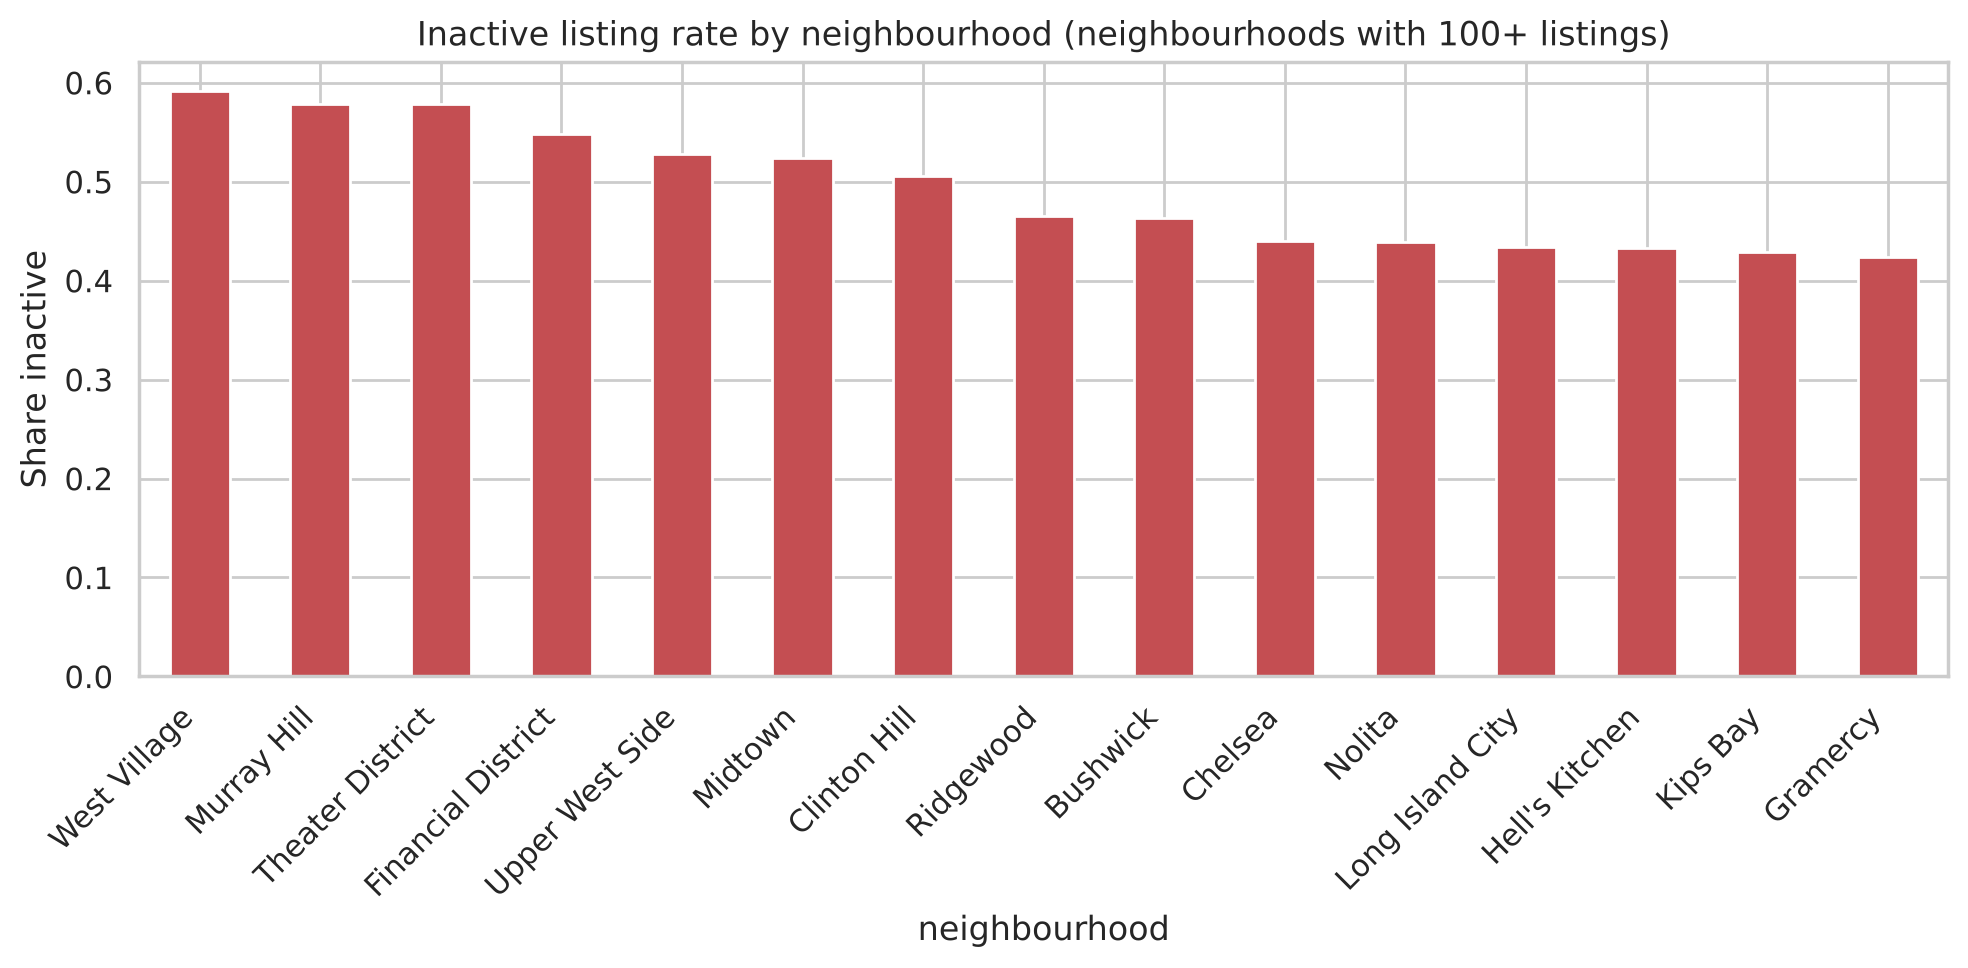

In [10]:
ref_date = df['last_review'].max()
df['inactive_2y'] = (df['last_review'].isna() | ((ref_date - df['last_review']).dt.days > 730)).astype(int)
print('Data snapshot date:', ref_date.date())
print(f"Inactive listings: {df['inactive_2y'].sum():,} ({df['inactive_2y'].mean():.1%})")

big = df['neighbourhood'].value_counts()
big = big[big >= 100].index
rate = df[df['neighbourhood'].isin(big)].groupby('neighbourhood')['inactive_2y'].mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 5))
rate.plot(kind='bar', color=sns.color_palette()[3])
plt.title('Inactive listing rate by neighbourhood (neighbourhoods with 100+ listings)')
plt.ylabel('Share inactive'); plt.xticks(rotation=45, ha='right')
save_show('inactive_rate_by_neighbourhood.png')

## 11. Grouped summaries

In [11]:
print('Top 10 hosts by number of listings:')
display(df.groupby(['host_id', 'host_name']).size().sort_values(ascending=False).head(10).rename('listings').to_frame())

summary = (df.groupby(['borough', 'room_type'])['price']
             .agg(listings='count', median='median', mean='mean')
             .round(1).sort_values('listings', ascending=False))
display(summary)

Top 10 hosts by number of listings:


,,listings
host_id,host_name,
107434423,Blueground,995
3223938,Eugene,362
446820235,LuxurybookingsFZE,320
533234561,Tina,255
162280872,Urban Furnished,227
51501835,Jeniffer,177
35491667,Nat,146
61391963,Darren,137
22541573,Furnished Quarters,132


listings  median   mean
borough       room_type                               
Manhattan     Entire home/apt      6537   255.0  336.8
Brooklyn      Entire home/apt      3748   185.0  233.9
              Private room         3482    79.0  106.2
Manhattan     Private room         2724   113.0  197.7
Queens        Private room         1862    76.0   94.7
              Entire home/apt      1429   150.0  192.1
Bronx         Private room          543    67.0   83.6
              Entire home/apt       363   130.0  162.7
Staten Island Private room          159    75.0   92.0
              Entire home/apt       157   120.0  158.7
Brooklyn      Shared room            72    43.0   92.0
Manhattan     Hotel room             61   403.0  650.0
Queens        Shared room            32    96.5  162.3
Manhattan     Shared room            32    66.0  216.5
Queens        Hotel room              6   224.0  209.7
Brooklyn      Hotel room              5   238.0  319.4
Staten Island Shared room             2    88.5   88.5

## 12. Hypotheses

In [12]:
# H1: Entire homes are more expensive than private / shared rooms
h1 = df.groupby('room_type')['price'].median().sort_values(ascending=False)
print('H1 median price by room type:\n', h1, '\n')

# H2: Listings with more reviews are booked more -> lower availability
r2 = df['number_of_reviews'].corr(df['availability_365'], method='spearman')
print(f'H2 Spearman(number_of_reviews, availability_365) = {r2:.3f}')

# H3: Multi-listing (commercial) hosts charge different prices than single hosts
h3 = df.groupby('is_multi_host')['price'].median()
print(f'H3 median price single host = ${h3[0]:.0f}, multi-listing host = ${h3[1]:.0f}')
r3 = df['host_listings_count'].corr(df['price'], method='spearman')
print(f'   Spearman(host_listings_count, price) = {r3:.3f}')

# H4: Manhattan is the most expensive borough
print('\nH4 median price by borough:\n', df.groupby('borough')['price'].median().sort_values(ascending=False))

H1 median price by room type:
 room_type
Hotel room         383.0
Entire home/apt    210.0
Private room        86.0
Shared room         59.0
Name: price, dtype: float64 

H2 Spearman(number_of_reviews, availability_365) = -0.181
H3 median price single host = $151, multi-listing host = $153
   Spearman(host_listings_count, price) = 0.074

H4 median price by borough:
 borough
Manhattan        222.0
Brooklyn         130.0
Queens           105.0
Staten Island    100.0
Bronx             90.0
Name: price, dtype: float64


## 13. Save cleaned data & executive summary

In [13]:
out_csv = DATA_CLEAN / 'listings_clean.csv'
df.to_csv(out_csv, index=False)

entire = df.loc[df['room_type'] == 'Entire home/apt', 'price'].median()
private = df.loc[df['room_type'] == 'Private room', 'price'].median()
top_borough = df.groupby('borough')['price'].median().idxmax()

print('EXECUTIVE SUMMARY')
print(f'- City: {CITY} | listings after cleaning: {len(df):,}')
print(f"- Median nightly price: ${df['price'].median():.0f} (mean ${df['price'].mean():.0f})")
print(f'- Entire homes cost ~{entire / private:.1f}x private rooms (${entire:.0f} vs ${private:.0f} median)')
print(f'- Most expensive borough: {top_borough}')
print(f"- {df['is_long_min_stay'].mean():.0%} of listings require 30+ night stays")
print(f"- {df['inactive_2y'].mean():.0%} of listings had no review in the last 2 years")
print(f'Saved: {out_csv.relative_to(BASE)}')

EXECUTIVE SUMMARY
- City: New York City | listings after cleaning: 21,214
- Median nightly price: $152 (mean $219)
- Entire homes cost ~2.4x private rooms ($210 vs $86 median)
- Most expensive borough: Manhattan
- 81% of listings require 30+ night stays
- 39% of listings had no review in the last 2 years
Saved: data/clean/listings_clean.csv


## 14. Bonus: host experience from the detailed listings file
If `data/raw/listings_detailed.csv` (Inside Airbnb *detailed* file) exists, merge `host_since` and compute
`host_experience_years`. **Fix vs. original version:** the original merged the column but never computed the feature.

In [14]:
detailed = DATA_RAW / 'listings_detailed.csv'
if detailed.exists():
    det = pd.read_csv(detailed, usecols=['id', 'host_since'], parse_dates=['host_since'])
    df = df.merge(det, on='id', how='left')
    df['host_experience_years'] = ((ref_date - df['host_since']).dt.days / 365.25).round(1)
    display(df['host_experience_years'].describe())
    display(df.groupby(pd.cut(df['host_experience_years'], [0, 2, 5, 10, 20]))['price'].median())
else:
    print('Optional file data/raw/listings_detailed.csv not found, skipping bonus step.')

Optional file data/raw/listings_detailed.csv not found, skipping bonus step.
